# Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.special import j0, j1

PODATKI = Path("../11_vaje/navodila")
if not PODATKI.exists():
    PODATKI = Path("../../11_vaje/navodila")

# Funkcije

In [2]:
# --- Naloga 1: palica (1D, FTCS) ---
def ftcs_1d(T, r, n_korakov):
    """n_korakov eksplicitne sheme FTCS; robni točki imata stalno temperaturo. r = D dt / dx^2."""
    T = T.copy()
    for _ in range(n_korakov):
        T[1:-1] = T[1:-1] + r * (T[2:] - 2 * T[1:-1] + T[:-2])
    return T


# --- Naloga 2: tla ---
def tla(T_pov, z, D, dt, T0, leta=2):
    """Temperatura v tleh pod površjem s temperaturo T_pov (urne vrednosti, linearno interpolirane).
    Spodnji rob (z[-1]) je adiabaten. Leto se ponovi leta-krat (prva leta za ustalitev).
    Vrne urne profile zadnjega leta, oblika (len(T_pov), len(z))."""
    r = D * dt / (z[1] - z[0])**2
    kor = int(round(3600 / dt))                      # korakov v eni uri
    T = np.full(len(z), float(T0))
    zap = np.empty((len(T_pov), len(z)))
    for _ in range(leta):
        for k in range(len(T_pov)):
            Ta, Tb = T_pov[k], T_pov[(k + 1) % len(T_pov)]
            for s in range(kor):
                T[0] = Ta + (Tb - Ta) * s / kor      # robni pogoj na površju
                lap = np.empty_like(T)
                lap[1:-1] = T[2:] - 2 * T[1:-1] + T[:-2]
                lap[-1] = 2 * (T[-2] - T[-1])
                T[1:] += r * lap[1:]
            zap[k] = T
    return zap


def harmonik(y, t, perioda):
    """Prilagodi y ~ a + b cos(w t) + c sin(w t) z w = 2 pi / perioda (linearni najmanjši kvadrati).
    Vrne amplitudo in fazo (faza narašča z zamikom)."""
    w = 2 * np.pi / perioda
    A = np.column_stack([np.ones_like(t), np.cos(w * t), np.sin(w * t)])
    a, b, c = np.linalg.lstsq(A, y, rcond=None)[0]
    return np.hypot(b, c), np.arctan2(c, b)


# --- Naloga 3: plošča, valj, krogla ---
def radialno(T0, T_ok, d, D, R, N, t_kon, r=0.15):
    """Ohlajanje/segrevanje telesa s polmerom R (d = 0 plošča s polovično debelino R, 1 valj, 2 krogla).
    Začetna temperatura T0, površje ima ves čas T_ok. Mreža r_i = i dr, i = 0..N.
    Vrne (časi, temperatura v središču, končni profil)."""
    dr = R / N
    dt = r * dr**2 / D
    n = int(np.ceil(t_kon / dt))
    T = np.full(N + 1, float(T0))
    T[-1] = T_ok
    i = np.arange(1, N)
    Tc = np.empty(n + 1)
    Tc[0] = T[0]
    for k in range(n):
        Tn = T.copy()
        Tn[i] = T[i] + r * (T[i + 1] - 2 * T[i] + T[i - 1] + d / (2 * i) * (T[i + 1] - T[i - 1]))
        Tn[0] = T[0] + r * (1 + d) * 2 * (T[1] - T[0])
        T = Tn
        Tc[k + 1] = T[0]
    return np.arange(n + 1) * dt, Tc, T


# --- Naloga 4: vogal stene (2D, stacionarno) ---
ZID, NOTRI, ZUNAJ, REZ = 0, 1, 2, 3


def vogal(a, d, h):
    """Prerez zunanjega vogala stene debeline d na območju a x a s celicami velikosti h.
    Vrne tabelo tipov celic z obrobo (n+2) x (n+2): zunaj pri x < 0 ali y < 0, rez (adiabatno) pri x, y > a."""
    n = int(round(a / h))
    xc = (np.arange(n) + 0.5) * h
    X, Y = np.meshgrid(xc, xc)
    tip = np.full((n + 2, n + 2), REZ)
    tip[1:-1, 1:-1] = np.where((X < d) | (Y < d), ZID, NOTRI)
    tip[0, :] = ZUNAJ
    tip[:, 0] = ZUNAJ
    return tip


def prevodnosti(tip, h, lam, h_i, h_e):
    """Prevodnosti [W/(m K)] med celico zidu in njenimi štirimi sosedi (gor, dol, levo, desno).
    Zid-zid: lam; zid-zrak: h / (h / (2 lam) + 1 / h_zrak); rez: 0."""
    G_zrak = {NOTRI: h / (h / (2 * lam) + 1 / h_i), ZUNAJ: h / (h / (2 * lam) + 1 / h_e)}
    sredina = tip[1:-1, 1:-1] == ZID
    G = []
    for s in (tip[:-2, 1:-1], tip[2:, 1:-1], tip[1:-1, :-2], tip[1:-1, 2:]):
        g = np.select([s == ZID, s == NOTRI, s == ZUNAJ], [lam, G_zrak[NOTRI], G_zrak[ZUNAJ]], 0.0)
        G.append(np.where(sredina, g, 0.0))
    return G


def jacobi(tip, G, T_i, T_e, T_zac, tol=1e-7, max_iter=100000):
    """Stacionarna temperatura zidu z Jacobijevo iteracijo: T celice = utežno povprečje sosedov (uteži G).
    Celice zraka imajo stalno temperaturo (T_i notri, T_e zunaj). Vrne (T z obrobo, število iteracij)."""
    zid = tip[1:-1, 1:-1] == ZID
    T = np.where(tip == NOTRI, T_i, np.where(tip == ZUNAJ, T_e, 0.0))
    T[1:-1, 1:-1][zid] = T_zac[zid]
    vsota_G = sum(G)
    for it in range(max_iter):
        sosedi = (T[:-2, 1:-1], T[2:, 1:-1], T[1:-1, :-2], T[1:-1, 2:])
        nov = sum(g * s for g, s in zip(G, sosedi))[zid] / vsota_G[zid]
        sprememba = np.abs(nov - T[1:-1, 1:-1][zid]).max()
        T[1:-1, 1:-1][zid] = nov
        if sprememba < tol:
            break
    return T, it + 1


def tok_notri(T, tip, G, T_i):
    """Toplotni tok [W/m] iz notranjega zraka v vsako celico zidu (n x n)."""
    q = np.zeros_like(G[0])
    for g, s in zip(G, (tip[:-2, 1:-1], tip[2:, 1:-1], tip[1:-1, :-2], tip[1:-1, 2:])):
        q += np.where(s == NOTRI, g * (T_i - T[1:-1, 1:-1]), 0.0)
    return q

# Testno območje

In [3]:
# P1: največji časovni korak za tla
D_tla = 5e-7
print(f"P1: dt_max (dx = 1 cm) = {0.5 * 0.01**2 / D_tla:.0f} s")
# P2: globina prodiranja
for ime, P, enota, s in (("dan", 86400, "h", 3600), ("leto", 365 * 86400, "dni", 86400)):
    delta = np.sqrt(2 * D_tla / (2 * np.pi / P))
    print(f"P2: {ime}: delta = {delta:.3f} m, zamik na globini delta = {P / (2 * np.pi) / s:.2f} {enota}")
# P3: lastne vrednosti in časovne konstante (enote R^2/D)
beta = {0: np.pi / 2, 1: brentq(j0, 2, 3), 2: np.pi}
for d, ime in ((0, "plošča"), (1, "valj"), (2, "krogla")):
    print(f"P3: {ime:7s} beta^2 = {beta[d]**2:.3f}, tau = {1 / beta[d]**2:.4f} R^2/D")
# P4: jajce
R_j, D_j = 0.022, 1.4e-7
print(f"P4: t(70 °C) = {R_j**2 / (np.pi**2 * D_j) * np.log(2 / (30 / 95)) / 60:.1f} min")

P1: dt_max (dx = 1 cm) = 100 s
P2: dan: delta = 0.117 m, zamik na globini delta = 3.82 h
P2: leto: delta = 2.240 m, zamik na globini delta = 58.09 dni
P3: plošča  beta^2 = 2.467, tau = 0.4053 R^2/D
P3: valj    beta^2 = 5.783, tau = 0.1729 R^2/D
P3: krogla  beta^2 = 9.870, tau = 0.1013 R^2/D
P4: t(70 °C) = 10.8 min


# Naloga 1 - Slika 2

r = 0.25: dt = 1.00 s, korakov = 1000, T(L/2) = 37.26 °C, analitično = 37.271 °C, največja napaka = 6.05e-03 °C
r = 0.45: dt = 1.80 s, korakov = 556, T(L/2) = 37.22 °C, analitično = 37.241 °C, največja napaka = 2.06e-02 °C
r = 0.50: dt = 2.00 s, korakov = 500, T(L/2) = 37.25 °C, analitično = 37.271 °C, največja napaka = 2.42e-02 °C
r = 0.55: dt = 2.20 s, korakov = 455, T(L/2) = 7.642e+19 °C, analitično = 37.234 °C, največja napaka = 1.22e+20 °C


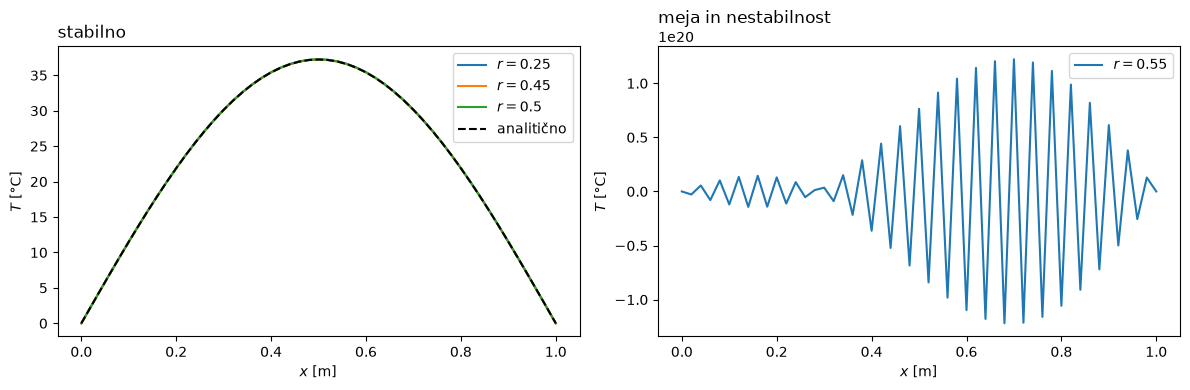

In [4]:
L, D_pal, N_pal = 1.0, 1e-4, 51
x = np.linspace(0, L, N_pal)
dx = x[1] - x[0]
tau_pal = L**2 / (np.pi**2 * D_pal)
T_zac = 100 * np.sin(np.pi * x / L)
fig = plt.figure(figsize=(12, 4))
ax1, ax2 = fig.add_subplot(121), fig.add_subplot(122)
for r in (0.25, 0.45, 0.50, 0.55):
    dt = r * dx**2 / D_pal
    n = int(round(1000 / dt))
    T = ftcs_1d(T_zac, r, n)
    T_an = T_zac * np.exp(-n * dt / tau_pal)
    napaka = np.abs(T - T_an).max()
    print(f"r = {r:.2f}: dt = {dt:.2f} s, korakov = {n}, T(L/2) = {T[N_pal // 2]:.4g} °C, "
          f"analitično = {T_an[N_pal // 2]:.3f} °C, največja napaka = {napaka:.2e} °C")
    if r <= 0.5:
        ax1.plot(x, T, label=f"$r = {r}$")
    else:
        ax2.plot(x, T, label=f"$r = {r}$")
ax1.plot(x, T_an, "k--", label="analitično")
ax1.set_title("stabilno", loc="left")
ax2.set_title("meja in nestabilnost", loc="left")
for ax in (ax1, ax2):
    ax.set_xlabel("$x$ [m]")
    ax.set_ylabel("$T$ [°C]")
    ax.legend()
fig.tight_layout()
plt.show()

# Naloga 2 - Slika 3

r = 0.375, povprečna temperatura zraka = 9.48 °C


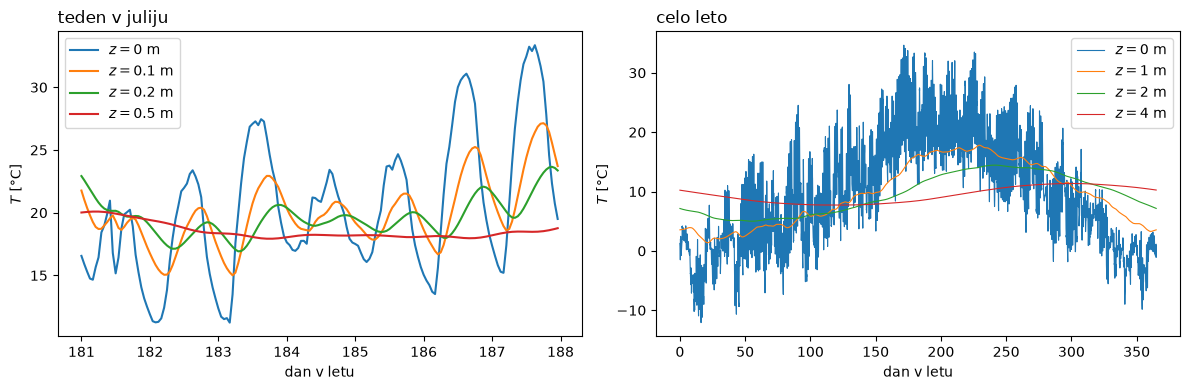

In [5]:
vreme = pd.read_csv(PODATKI / "Vreme_urni.csv")
T_zrak = vreme["T"].to_numpy()
dz, H = 0.02, 8.0
z = np.arange(0, H + dz / 2, dz)
dt_tla = 300.0
print(f"r = {D_tla * dt_tla / dz**2:.3f}, povprečna temperatura zraka = {T_zrak.mean():.2f} °C")
zap = tla(T_zrak, z, D_tla, dt_tla, T_zrak.mean())
ure = np.arange(len(T_zrak)) / 24
fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(121)
for zi in (0, 0.1, 0.2, 0.5):
    ax.plot(ure[4344:4344 + 168], zap[4344:4344 + 168, int(round(zi / dz))], label=f"$z = {zi}$ m")
ax.set_xlabel("dan v letu")
ax.set_ylabel("$T$ [°C]")
ax.set_title("teden v juliju", loc="left")
ax.legend()
ax = fig.add_subplot(122)
for zi in (0, 1, 2, 4):
    ax.plot(ure, zap[:, int(round(zi / dz))], lw=0.8, label=f"$z = {zi}$ m")
ax.set_xlabel("dan v letu")
ax.set_ylabel("$T$ [°C]")
ax.set_title("celo leto", loc="left")
ax.legend()
fig.tight_layout()
plt.show()

# Naloga 2 - Slika 4

z = 0.0 m: dnevna A = 4.502 °C, zamik =  0.00 h; letna A = 11.35 °C, zamik =   0.0 dni
z = 0.1 m: dnevna A = 1.918 °C, zamik =  3.18 h; letna A = 10.86 °C, zamik =   2.6 dni
z = 0.2 m: dnevna A = 0.820 °C, zamik =  6.45 h; letna A = 10.38 °C, zamik =   5.2 dni
z = 0.5 m: dnevna A = 0.064 °C, zamik = 16.25 h; letna A = 9.09 °C, zamik =  13.0 dni
z = 1.0 m: dnevna A = 0.001 °C, zamik =  8.57 h; letna A = 7.27 °C, zamik =  25.9 dni
z = 2.0 m: dnevna A = 0.000 °C, zamik =  3.90 h; letna A = 4.66 °C, zamik =  51.6 dni
z = 4.0 m: dnevna A = 0.000 °C, zamik =  3.93 h; letna A = 1.86 °C, zamik = 102.9 dni
delta (dan) = 0.117 m
delta (leto) = 2.22 m


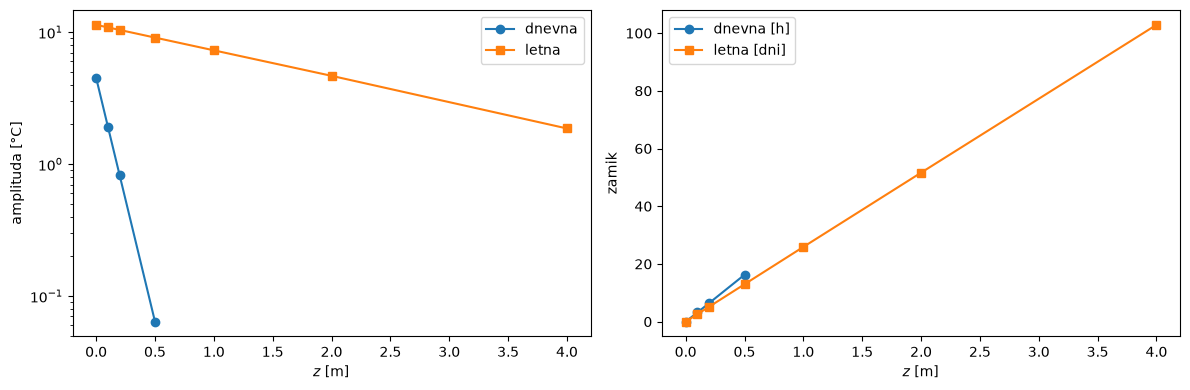

In [6]:
globine = np.array([0, 0.1, 0.2, 0.5, 1, 2, 4])
t_ure = np.arange(len(T_zrak)) + 1.0                 # profil je zapisan ob koncu ure
A_d, f_d, A_l, f_l = (np.empty(len(globine)) for _ in range(4))
for k, zi in enumerate(globine):
    y = zap[:, int(round(zi / dz))]
    A_d[k], f_d[k] = harmonik(y, t_ure, 24.0)
    A_l[k], f_l[k] = harmonik(y, t_ure, 8760.0)
zam_d = (np.unwrap(f_d) - f_d[0]) * 24 / (2 * np.pi)          # [h]
zam_l = (np.unwrap(f_l) - f_l[0]) * 365 / (2 * np.pi)         # [dni]
for k, zi in enumerate(globine):
    print(f"z = {zi:3.1f} m: dnevna A = {A_d[k]:.3f} °C, zamik = {zam_d[k]:5.2f} h; "
          f"letna A = {A_l[k]:.2f} °C, zamik = {zam_l[k]:5.1f} dni")
m = globine <= 0.2
print(f"delta (dan) = {-1 / np.polyfit(globine[m], np.log(A_d[m]), 1)[0]:.3f} m")
print(f"delta (leto) = {-1 / np.polyfit(globine, np.log(A_l), 1)[0]:.2f} m")
fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(121)
ax.semilogy(globine[:4], A_d[:4], "o-", label="dnevna")
ax.semilogy(globine, A_l, "s-", label="letna")
ax.set_xlabel("$z$ [m]")
ax.set_ylabel("amplituda [°C]")
ax.legend()
ax = fig.add_subplot(122)
ax.plot(globine[:4], zam_d[:4], "o-", label="dnevna [h]")
ax.plot(globine, zam_l, "s-", label="letna [dni]")
ax.set_xlabel("$z$ [m]")
ax.set_ylabel("zamik")
ax.legend()
fig.tight_layout()
plt.show()

# Naloga 3 - Slika 5

plošča : tau = 1401 s (teorija 1401 s), t(70 °C) = 32.6 min (prvi člen vrste 32.6 min)


valj   : tau = 598 s (teorija 598 s), t(70 °C) = 16.2 min (prvi člen vrste 16.2 min)


krogla : tau = 350 s (teorija 350 s), t(70 °C) = 10.8 min (prvi člen vrste 10.8 min)


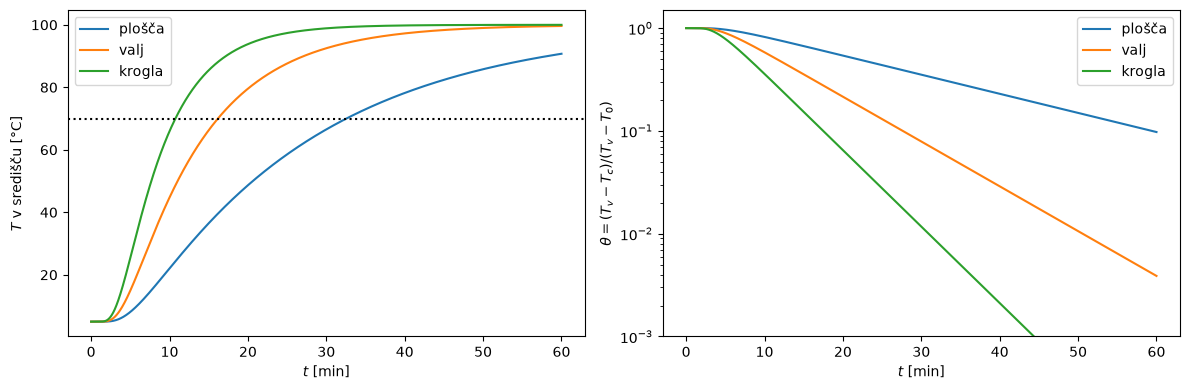

In [7]:
T_hlad, T_voda, N_r = 5.0, 100.0, 44
koef = {0: 4 / np.pi, 1: 2 / (beta[1] * j1(beta[1])), 2: 2.0}   # prvi člen vrste v središču
fig = plt.figure(figsize=(12, 4))
ax1, ax2 = fig.add_subplot(121), fig.add_subplot(122)
for d, ime in ((0, "plošča"), (1, "valj"), (2, "krogla")):
    t, Tc, prof = radialno(T_hlad, T_voda, d, D_j, R_j, N_r, 3600)
    theta = (T_voda - Tc) / (T_voda - T_hlad)
    m = (theta < 0.3) & (theta > 0.01)
    tau_fit = -1 / np.polyfit(t[m], np.log(theta[m]), 1)[0]
    tau_teo = R_j**2 / (beta[d]**2 * D_j)
    t70 = t[np.argmax(Tc >= 70)]
    t70_teo = tau_teo * np.log(koef[d] / (30 / 95))
    print(f"{ime:7s}: tau = {tau_fit:.0f} s (teorija {tau_teo:.0f} s), "
          f"t(70 °C) = {t70 / 60:.1f} min (prvi člen vrste {t70_teo / 60:.1f} min)")
    ax1.plot(t / 60, Tc, label=ime)
    ax2.semilogy(t / 60, theta, label=ime)
ax1.axhline(70, color="k", ls=":")
ax1.set_xlabel("$t$ [min]")
ax1.set_ylabel("$T$ v središču [°C]")
ax1.legend()
ax2.set_xlabel("$t$ [min]")
ax2.set_ylabel(r"$\theta = (T_v - T_c)/(T_v - T_0)$")
ax2.set_ylim(1e-3, 1.5)
ax2.legend()
fig.tight_layout()
plt.show()

# Naloga 4 - Slika 6

lam = 0.8: iteracij = 7786, U = 1.835 W/(m2K), Q = 115.8 W/m (ravna stena 110.1), psi = 0.227 W/(mK), T_si: ravna 14.04 °C, vogal 10.60 °C, f_Rsi: 0.76 / 0.62


lam = 0.2: iteracij = 5593, U = 0.599 W/(m2K), Q = 38.2 W/m (ravna stena 35.9), psi = 0.089 W/(mK), T_si: ravna 18.05 °C, vogal 15.88 °C, f_Rsi: 0.92 / 0.84


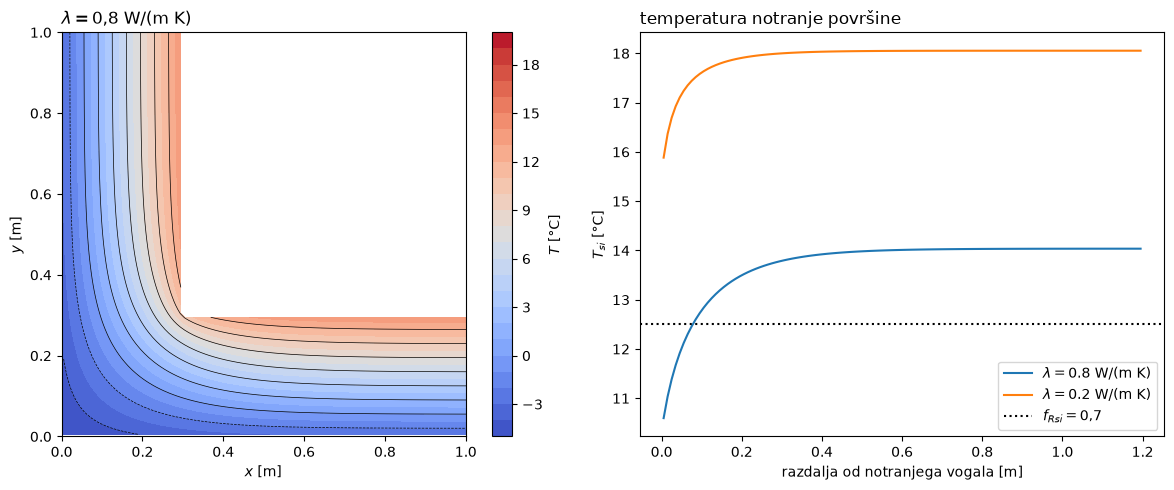

In [8]:
a_v, d_st, h_v = 1.5, 0.30, 0.01
h_i, h_e, T_i, T_e = 1 / 0.13, 1 / 0.04, 20.0, -5.0
tip = vogal(a_v, d_st, h_v)
n_v = tip.shape[0] - 2
xc = (np.arange(n_v) + 0.5) * h_v
X, Y = np.meshgrid(xc, xc)
zid = tip[1:-1, 1:-1] == ZID
L_n = 2 * (a_v - d_st)                                 # notranja dolžina obeh krakov
rezultati = {}
for lam in (0.8, 0.2):
    U = 1 / (1 / h_i + d_st / lam + 1 / h_e)
    T_zac = T_e + (T_i - T_e) * U * (1 / h_e + np.minimum(X, Y) / lam)     # 1D profil ravne stene
    G = prevodnosti(tip, h_v, lam, h_i, h_e)
    T, n_it = jacobi(tip, G, T_i, T_e, T_zac)
    q = tok_notri(T, tip, G, T_i)
    Q = q.sum()
    psi = (Q - U * L_n * (T_i - T_e)) / (T_i - T_e)
    T_si = np.where(q > 0, T_i - q / h_v / h_i, np.nan)   # površinska temperatura notranje strani
    T_si_min, T_si_rav = np.nanmin(T_si), T_i - U * (T_i - T_e) / h_i
    f = lambda Ts: (Ts - T_e) / (T_i - T_e)
    print(f"lam = {lam}: iteracij = {n_it}, U = {U:.3f} W/(m2K), Q = {Q:.1f} W/m "
          f"(ravna stena {U * L_n * (T_i - T_e):.1f}), psi = {psi:.3f} W/(mK), "
          f"T_si: ravna {T_si_rav:.2f} °C, vogal {T_si_min:.2f} °C, f_Rsi: {f(T_si_rav):.2f} / {f(T_si_min):.2f}")
    rezultati[lam] = (T, T_si)
T = rezultati[0.8][0]
nd = int(round(d_st / h_v))
fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(121)
Tz = np.where(zid, T[1:-1, 1:-1], np.nan)
cs = ax.contourf(X, Y, Tz, levels=np.arange(-5, 21, 1), cmap="coolwarm")
ax.contour(X, Y, Tz, levels=np.arange(-4, 20, 2), colors="k", linewidths=0.5)
fig.colorbar(cs, ax=ax, label="$T$ [°C]")
ax.set_xlim(0, 1.0)
ax.set_ylim(0, 1.0)
ax.set_aspect("equal")
ax.set_xlabel("$x$ [m]")
ax.set_ylabel("$y$ [m]")
ax.set_title(r"$\lambda = 0{,}8$ W/(m K)", loc="left")
ax = fig.add_subplot(122)
for lam, (T_, T_si) in rezultati.items():
    ax.plot(xc[nd:] - d_st, T_si[nd:, nd - 1], label=rf"$\lambda = {lam}$ W/(m K)")   # notranja površina navpičnega kraka
ax.axhline(T_e + 0.7 * (T_i - T_e), color="k", ls=":", label="$f_{Rsi} = 0{,}7$")
ax.set_xlabel("razdalja od notranjega vogala [m]")
ax.set_ylabel("$T_{si}$ [°C]")
ax.set_title("temperatura notranje površine", loc="left")
ax.legend()
fig.tight_layout()
plt.show()